
# <font color="blue"> Taller Práctico: Generación de Imágenes con Stable Diffusion</font>

### <font color="red">Alfredo Diaz Claro</font>

### Usando 🤗 Hugging Face Diffusers en Google Colab



## ¿Qué aprenderás en este taller?

| Módulo | Tema |
|--------|------|
| 1 | Conceptos fundamentales de los modelos de difusión |
| 2 | Configuración del entorno en Google Colab |
| 3 | Generación básica de imágenes (Text-to-Image) |
| 4 | Técnicas de Prompt Engineering |
| 5 | Parámetros avanzados: CFG, Steps, Seeds |
| 6 | Image-to-Image e Inpainting |

---

##  Conceptos Fundamentales

### ¿Qué es Stable Diffusion?

**Stable Diffusion** es un modelo generativo de imágenes basado en **difusión latente** (*Latent Diffusion Model*, LDM). Fue desarrollado por **Stability AI** en colaboración con Ludwig Maximilian University of Munich y Runway ML.

### ¿Cómo funciona?

El proceso de difusión ocurre en **dos etapas**:

```
ENTRENAMIENTO (Forward Process)
Imagen original → Añadir ruido progresivamente → Ruido puro (gaussian noise)

INFERENCIA (Reverse Process)
Ruido puro → Eliminar ruido paso a paso (guiado por el prompt) → Imagen generada
```

### Componentes principales del pipeline:

1. **Text Encoder (CLIP)**: Convierte el prompt de texto en *embeddings* vectoriales
2. **VAE Encoder/Decoder**: Comprime y descomprime imágenes al espacio latente
3. **U-Net**: Red neuronal que aprende a eliminar ruido en el espacio latente
4. **Scheduler**: Controla el proceso de eliminación de ruido paso a paso

```
Prompt ──→ [CLIP Text Encoder] ──→ Embeddings
                                        │
                                        ▼
Ruido ──────────────────────────→ [U-Net] ──→ Latente limpio
                 (cross-attention con embeddings)      │
                                                       ▼
                                              [VAE Decoder] ──→ Imagen Final
```

### Versiones disponibles:

| Versión | ID en Hugging Face | VRAM mínima | Notas |
|---------|-------------------|-------------|-------|
| SD 1.4 | `CompVis/stable-diffusion-v1-4` | ~4 GB | Primera versión pública |
| SD 1.5 | `runwayml/stable-diffusion-v1-5` | ~4 GB | Más estable, comunidad activa |
| SD 2.0 | `stabilityai/stable-diffusion-2` | ~6 GB | Resolución 512x512 |
| SD 2.1 | `stabilityai/stable-diffusion-2-1` | ~6 GB | Resolución 768x768, mejor calidad |
| SDXL 1.0 | `stabilityai/stable-diffusion-xl-base-1.0` | ~8 GB | 1024x1024, estado del arte |
| SDXL Turbo | `stabilityai/sdxl-turbo` | ~8 GB | Generación en 1-4 pasos |

> ** Recomendación para este taller**: Usaremos `stable-diffusion-2-1` que ofrece excelente calidad con los recursos de Colab (GPU T4 con ~15 GB VRAM).

---

## Módulo 1: Verificar el entorno GPU

Google Colab ofrece acceso gratuito a GPUs NVIDIA. Para este taller necesitamos:
- **GPU**: NVIDIA T4 o superior (la T4 tiene ~15 GB VRAM)
- **RAM del sistema**: mínimo 12 GB

> **IMPORTANTE**: Ve a `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU` antes de continuar.

In [26]:
# Verificar disponibilidad y tipo de GPU
import subprocess

result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout)

# Verificar con PyTorch
import torch
print(f"\n PyTorch versión: {torch.__version__}")
print(f"CUDA disponible: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f" GPU detectada: {torch.cuda.get_device_name(0)}")
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f" VRAM total: {total_vram:.1f} GB")
else:
    print(" GPU no disponible. Ve a Entorno de ejecución → Cambiar tipo de entorno → GPU")

Fri Nov 13 20:25:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   65C    P0             30W /   70W |    8591MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

##  Módulo 2: Instalación de dependencias

La biblioteca principal es **🤗 Diffusers** de Hugging Face. Instalaremos:

- `diffusers`: Pipeline principal con modelos y schedulers
- `transformers`: Para el encoder de texto (CLIP)
- `accelerate`: Optimización de inferencia en GPU
- `xformers`: Optimización de memoria con *attention efficient* (opcional pero recomendado)
- `safetensors`: Formato seguro para cargar pesos del modelo

>  **Versiones fijadas** para reproducibilidad. La instalación tarda ~2 minutos.

In [27]:
!pip list | grep diffusers

diffusers                             0.42.1


In [28]:
!pip list | grep accelerate

accelerate                            1.15.0


In [29]:
!pip list | grep transformers

sentence-transformers                 5.7.0
transformers                          5.22.1


In [30]:
!pip list | grep safetensors

safetensors                           0.8.0


In [31]:
!pip list |grep Pillow

In [32]:
!pip list|grep invisible_watermark

In [33]:
!pip list|grep omegaconf

omegaconf                             2.4.0


In [34]:
!pip list|grep huggingface_hub

huggingface_hub                       1.33.0


In [35]:
# Instalación de todas las dependencias con versiones específicas
!pip install -q Pillow  invisible_watermark

print(" Instalación completada")

 Instalación completada


In [36]:
# Verificar versiones instaladas
import diffusers
import transformers
import accelerate
from PIL import Image
import IPython.display as display
import matplotlib.pyplot as plt
import numpy as np

print(" Versiones instaladas:")
print(f"  diffusers:      {diffusers.__version__}")
print(f"  transformers:   {transformers.__version__}")
print(f"  accelerate:     {accelerate.__version__}")
print(f"  torch:          {torch.__version__}")
print(f"  Pillow:         {Image.__version__}")
print("\n Entorno listo para comenzar")

 Versiones instaladas:
  diffusers:      0.42.1
  transformers:   5.22.1
  accelerate:     1.15.0
  torch:          2.14.1+cu130
  Pillow:         11.3.0

 Entorno listo para comenzar


##  Módulo 3: Carga del Modelo – Text-to-Image básico

### ¿Qué es `StableDiffusionPipeline`?

Es la clase principal de `diffusers` que encapsula todos los componentes del modelo en un solo objeto fácil de usar. Internamente gestiona:
- La descarga y caché del modelo desde Hugging Face Hub
- La asignación de memoria en GPU
- El loop de difusión (añadir/quitar ruido)

### Parámetros clave de `from_pretrained()`:

| Parámetro | Descripción | Valor recomendado |
|-----------|-------------|------------------|
| `torch_dtype` | Precisión numérica del modelo | `torch.float16` (mitad de memoria) |
| `use_safetensors` | Usar formato seguro de carga | `True` |
| `variant` | Variante del modelo | `"fp16"` para GPU |

>  **La descarga del modelo (~5 GB) puede tomar 3-5 minutos** la primera vez. Colab lo cachea para sesiones futuras.

In [37]:
import getpass

HF_TOKEN = getpass.getpass('Pega aquí tu token de Hugging Face: ')

if not HF_TOKEN:
    raise ValueError('No se introdujo ningún token de Hugging Face.')

print('Token de Hugging Face cargado correctamente.')

Token de Hugging Face cargado correctamente.


In [38]:
import torch
from diffusers import DiffusionPipeline

# ─────────────────────────────────────────────────────
# SELECCIÓN DEL MODELO
# Cambia MODEL_ID para experimentar con distintas versiones
# ─────────────────────────────────────────────────────
#MODEL_ID = "stabilityai/stable-diffusion-2-1"
# MODEL_ID = "runwayml/stable-diffusion-v1-5"       # Alternativa SD 1.5
# MODEL_ID = "stabilityai/sdxl-turbo"               # Muy rápido, baja memoria
# Ejemplo usando SD 3.5 Medium:
MODEL_ID = "stabilityai/stable-diffusion-3.5-medium"

# Ejemplo usando FLUX.1 Schnell:
# MODEL_ID = "black-forest-labs/FLUX.1-schnell"

print(f" Cargando modelo: {MODEL_ID}")
print(" Esto puede tomar varios minutos la primera vez...")

# Cargar el pipeline completo
pipe = DiffusionPipeline.from_pretrained(
    "sd2-community/stable-diffusion-2-1",
    token=HF_TOKEN,
    dtype=torch.bfloat16,
    device_map="cuda"
)

# Mover el modelo a la GPU
pipe = pipe.to("cuda")

# Habilitar attention slicing (alternativa si xformers no está disponible)
pipe.enable_attention_slicing()

print("\n Modelo cargado correctamente en GPU")
vram_used = torch.cuda.memory_allocated() / 1e9
print(f" VRAM utilizada por el modelo: {vram_used:.2f} GB")

 Cargando modelo: stabilityai/stable-diffusion-3.5-medium
 Esto puede tomar varios minutos la primera vez...


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]


 Modelo cargado correctamente en GPU
 VRAM utilizada por el modelo: 5.19 GB


##  Módulo 4: Primera Generación de Imagen

### El objeto `pipeline()` acepta estos parámetros principales:

| Parámetro | Tipo | Descripción | Valor por defecto |
|-----------|------|-------------|------------------|
| `prompt` | `str` | Descripción en texto de la imagen deseada | (requerido) |
| `negative_prompt` | `str` | Lo que NO quieres que aparezca | `None` |
| `num_inference_steps` | `int` | Pasos de denoising (más = mejor calidad, más lento) | `50` |
| `guidance_scale` | `float` | Qué tan fiel seguir el prompt (CFG scale) | `7.5` |
| `height` | `int` | Alto de la imagen en píxeles | `512` |
| `width` | `int` | Ancho de la imagen en píxeles | `512` |
| `generator` | `torch.Generator` | Semilla para reproducibilidad | `None` |
| `num_images_per_prompt` | `int` | Cuántas imágenes generar a la vez | `1` |

In [39]:
# Función helper para mostrar imágenes de forma elegante
def mostrar_imagen(imagen, titulo="Imagen generada", guardar=False, nombre="output.png"):
    """Muestra una imagen PIL en el notebook con título y opción de guardar."""
    plt.figure(figsize=(8, 8))
    plt.imshow(imagen)
    plt.title(titulo, fontsize=14, pad=12)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    if guardar:
        imagen.save(nombre)
        print(f" Imagen guardada como: {nombre}")

def mostrar_galeria(imagenes, titulos=None, cols=2):
    """Muestra una galería de imágenes en grid."""
    n = len(imagenes)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(8 * cols, 8 * rows))
    axes = axes.flatten() if n > 1 else [axes]
    for i, (ax, img) in enumerate(zip(axes, imagenes)):
        ax.imshow(img)
        ax.axis('off')
        if titulos and i < len(titulos):
            ax.set_title(titulos[i], fontsize=12)
    for ax in axes[n:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

print(" Funciones auxiliares definidas")

 Funciones auxiliares definidas


## Usando stable-diffusion-3.5-medium
. Acepta las condiciones en Hugging Face Inicia sesión en huggingface.co.

Entra a la página del modelo: https://huggingface.co/stabilityai/stable-diffusion-3.5-medium.

En la parte superior verás un formulario de condiciones. Completa la información solicitada y haz clic en "Agree and access repository" (o aceptar términos). La aprobación suele ser instantánea.

Pasa el token en tu código de Python Asegúrate de pasar tu HF_TOKEN directamente en el parámetro token del método from_pretrained.

## Un negative prompt (o prompt negativo)
Es una instrucción que le indica al modelo de Inteligencia Artificial qué elementos, errores o cualidades debe evitar o eliminar durante el proceso de generación de la imagen.

La variable negative_prompt_base guarda un conjunto estándar de palabras clave desaprobadas para aplicarlas de forma automática a tus generaciones.

blurry: Evita que la imagen quede fuera de foco, borrosa o con falta de nitidez.

low quality: Reduce artefactos de baja resolución, píxeles ruidosos o acabados de pobre calidad visual.

ugly: Guía al modelo lejos de composiciones estéticamente desagradables o proporciones extrañas.

deformed: Ayuda a prevenir anatomías alteradas (como manos con dedos extra, extremidades dobladas de forma unnatural o rostros desfigurados).

watermark: Evita que el modelo dibuje marcas de agua, firmas de fotógrafos o logos simulados (comunes en conjuntos de datos extraídos de bancos de imágenes).

In [40]:
# ─────────────────────────────────────────────────────
# GENERACIÓN BÁSICA – Ejemplo 1
# ─────────────────────────────────────────────────────

# Fijar semilla para reproducibilidad
SEED = 42
generator = torch.Generator(device="cuda").manual_seed(SEED)

#prompt = (
#    "a serene japanese garden at sunset, cherry blossoms, "
#    "koi pond, wooden bridge, golden hour lighting, "
#    "photorealistic, 8k, detailed"
#)

prompt= (
    "Fotografía cinematográfica de un estudiante explorando una selva densa y misteriosa  con un computador en mano,"
    "Iluminación suave y difusa con tonos fríos de azul, cian y verde musgo apagado."
)

negative_prompt = (
    "blurry, low quality, distorted, ugly, bad anatomy, "
    "watermark, text, noise, artifacts"
)


print(f" Generando imagen...")
print(f"   Prompt: {prompt[:60]}...")
print(f"   Seed: {SEED}")

resultado = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=30,     # 30 pasos: buena calidad, tiempo razonable (~25 seg en T4)
    guidance_scale=7.5,          # CFG clásico para SD 2.1
    height=768,                  # SD 2.1 está optimizado para 768x768
    width=768,
    generator=generator
)



 Generando imagen...
   Prompt: Fotografía cinematográfica de un estudiante explorando una s...
   Seed: 42


  0%|          | 0/30 [00:00<?, ?it/s]

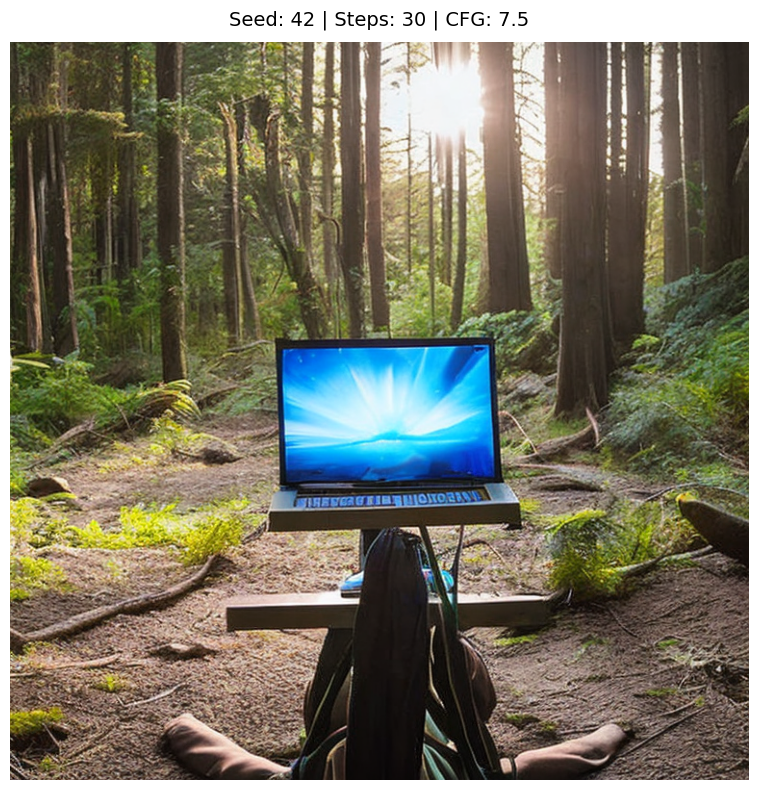

 Imagen guardada como: astronauta.png


In [41]:
imagen = resultado.images[0]
#mostrar_imagen(imagen, titulo=f"Seed: {SEED} | Steps: 30 | CFG: 7.5", guardar=True, nombre="jardin_japones.png")
mostrar_imagen(imagen, titulo=f"Seed: {SEED} | Steps: 30 | CFG: 7.5", guardar=True, nombre="astronauta.png")

##  Módulo 5: Prompt Engineering

El **prompt engineering** es el arte de escribir descripciones efectivas para guiar al modelo. Un buen prompt generalmente incluye:

```
[SUJETO PRINCIPAL] + [ESTILO ARTÍSTICO] + [ILUMINACIÓN] + [COMPOSICIÓN] + [CALIDAD]
```

### Modificadores de calidad más efectivos:

| Categoría | Ejemplos |
|-----------|----------|
| **Calidad general** | `masterpiece`, `best quality`, `ultra-detailed`, `4K`, `8K` |
| **Estilos fotográficos** | `photorealistic`, `DSLR photo`, `bokeh`, `golden hour` |
| **Estilos artísticos** | `oil painting`, `watercolor`, `digital art`, `concept art`, `by Greg Rutkowski` |
| **Iluminación** | `dramatic lighting`, `soft lighting`, `cinematic lighting`, `volumetric light` |
| **Composición** | `close-up`, `wide shot`, `bird's eye view`, `rule of thirds` |

### Negative Prompts más comunes:
```
ugly, deformed, noisy, blurry, low quality, bad anatomy,
extra limbs, disfigured, cropped, watermark, signature, text
```


 Generando imagen 1/2: 'a cat'


  0%|          | 0/30 [00:00<?, ?it/s]


 Generando imagen 2/2: 'A majestic Persian cat sitting on a velvet throne ...'


  0%|          | 0/30 [00:00<?, ?it/s]

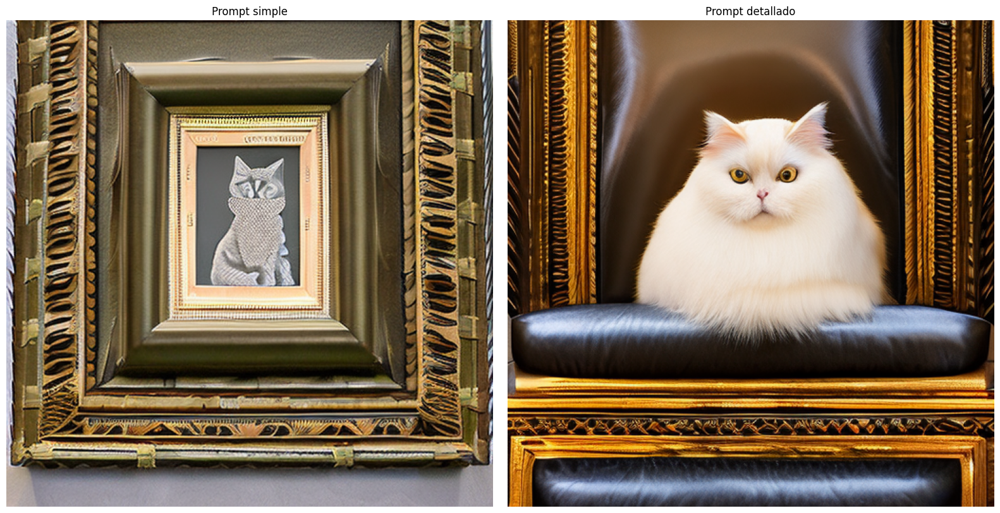


 Observa la diferencia de calidad y detalle entre los dos prompts


In [42]:
# ─────────────────────────────────────────────────────
# EXPERIMENTO: Comparación de prompts
# Mismo seed, diferente nivel de detalle en el prompt
# ─────────────────────────────────────────────────────

SEED_COMP = 42
negative_prompt_base = "blurry, low quality, ugly, deformed, watermark"

prompts_comparacion = [
    # Prompt simple
    "a cat",
    # Prompt detallado
    "A majestic Persian cat sitting on a velvet throne dressed as Batman., "
    "royal portrait, dramatic lighting, oil painting style, "
    "rich colors, detailed fur texture, 8k"
]

etiquetas = ["Prompt simple", "Prompt detallado"]
imagenes_comp = []

for i, prompt in enumerate(prompts_comparacion):
    print(f"\n Generando imagen {i+1}/2: '{prompt[:50]}...'" if len(prompt) > 50 else f"\n Generando imagen {i+1}/2: '{prompt}'")
    gen = torch.Generator(device="cuda").manual_seed(SEED_COMP)
    resultado = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt_base,
        num_inference_steps=30,
        guidance_scale=7.5,
        height=512, width=512,
        generator=gen
    )
    imagenes_comp.append(resultado.images[0])

mostrar_galeria(imagenes_comp, titulos=etiquetas, cols=2)
print("\n Observa la diferencia de calidad y detalle entre los dos prompts")

##  Módulo 6: Parámetros Avanzados

### `guidance_scale` (CFG Scale)

El **Classifier-Free Guidance** controla qué tanto el modelo sigue el prompt vs. genera libremente:

```
CFG = 1.0  → Ignora casi por completo el prompt (muy creativo, caótico)
CFG = 7.5  → Balance ideal (valor por defecto recomendado)
CFG = 15+  → Sigue el prompt rígidamente (puede verse saturado o irreal)
```

### `num_inference_steps`

Número de pasos del proceso de denoising:
- **20 pasos**: Rápido (~15 seg), calidad aceptable
- **30-40 pasos**: Balance ideal
- **50 pasos**: Máxima calidad, ~35 seg en T4
- **100+ pasos**: Rendimientos decrecientes, no recomendado

### Semillas (`seed`)

La semilla inicializa el ruido gaussiano de partida. Mismo prompt + misma semilla = misma imagen siempre.

  Generando con CFG = 3.0...


  0%|          | 0/30 [00:00<?, ?it/s]

  Generando con CFG = 7.5...


  0%|          | 0/30 [00:00<?, ?it/s]

  Generando con CFG = 12.0...


  0%|          | 0/30 [00:00<?, ?it/s]

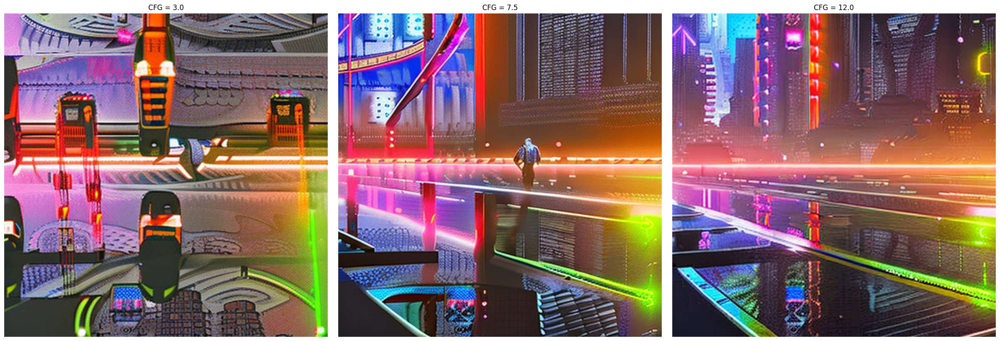


 Nota cómo CFG bajo = más libertad creativa, CFG alto = más fidelidad al prompt


In [43]:
# ─────────────────────────────────────────────────────
# EXPERIMENTO: Efecto del CFG Scale
# ─────────────────────────────────────────────────────

prompt_cfg = "a futuristic cyberpunk city at night, neon lights, rain, cinematic"
negative_cfg = "blurry, low quality, ugly"
SEED_CFG = 999

cfg_values = [3.0, 7.5, 12.0]
imagenes_cfg = []

for cfg in cfg_values:
    print(f"  Generando con CFG = {cfg}...")
    gen = torch.Generator(device="cuda").manual_seed(SEED_CFG)
    resultado = pipe(
        prompt=prompt_cfg,
        negative_prompt=negative_cfg,
        num_inference_steps=30,
        guidance_scale=cfg,
        height=512, width=512,
        generator=gen
    )
    imagenes_cfg.append(resultado.images[0])

mostrar_galeria(
    imagenes_cfg,
    titulos=[f"CFG = {v}" for v in cfg_values],
    cols=3
)
print("\n Nota cómo CFG bajo = más libertad creativa, CFG alto = más fidelidad al prompt")

🌱 Generando con seed = 42...


  0%|          | 0/25 [00:00<?, ?it/s]

🌱 Generando con seed = 100...


  0%|          | 0/25 [00:00<?, ?it/s]

🌱 Generando con seed = 777...


  0%|          | 0/25 [00:00<?, ?it/s]

🌱 Generando con seed = 2024...


  0%|          | 0/25 [00:00<?, ?it/s]

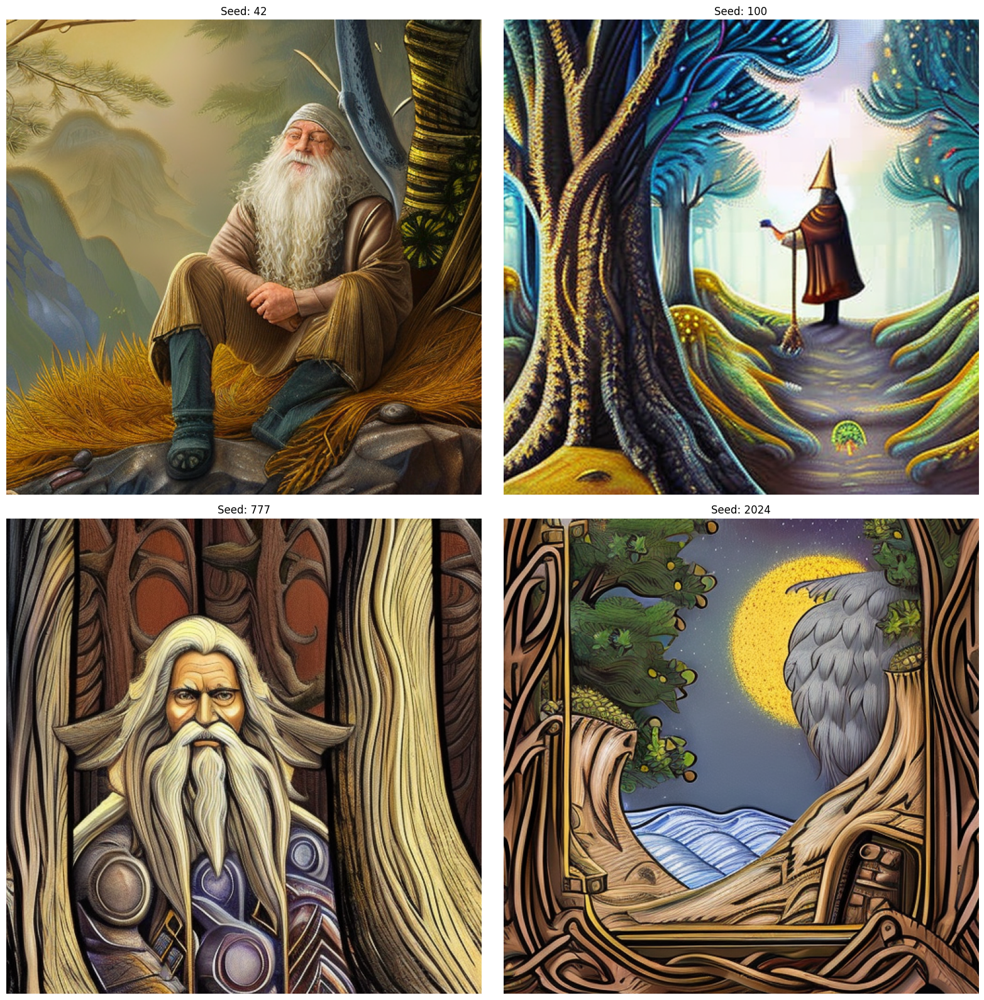


 Con el mismo prompt pero distintas semillas obtienes variaciones únicas


In [44]:
# ─────────────────────────────────────────────────────
# EXPERIMENTO: Múltiples semillas – variaciones del mismo prompt
# ─────────────────────────────────────────────────────

prompt_seeds = (
    "portrait of a wise old wizard, magical forest background, "
    "mystical atmosphere, detailed, fantasy art"
)
negative_seeds = "blurry, ugly, deformed, extra limbs, watermark"

seeds = [42, 100, 777, 2024]
imagenes_seeds = []

for seed in seeds:
    print(f"🌱 Generando con seed = {seed}...")
    gen = torch.Generator(device="cuda").manual_seed(seed)
    resultado = pipe(
        prompt=prompt_seeds,
        negative_prompt=negative_seeds,
        num_inference_steps=25,
        guidance_scale=7.5,
        height=512, width=512,
        generator=gen
    )
    imagenes_seeds.append(resultado.images[0])

mostrar_galeria(imagenes_seeds, titulos=[f"Seed: {s}" for s in seeds], cols=2)
print("\n Con el mismo prompt pero distintas semillas obtienes variaciones únicas")

##  Módulo 7: Schedulers (Samplers)

El **scheduler** define el algoritmo matemático usado para el proceso de denoising. Distintos schedulers producen resultados ligeramente diferentes con el mismo número de pasos.

| Scheduler | Clase | Características |
|-----------|-------|----------------|
| **DDIM** | `DDIMScheduler` | Clásico, predecible, bueno en pocos pasos |
| **PNDM** | `PNDMScheduler` | Por defecto en SD, balance velocidad/calidad |
| **Euler** | `EulerDiscreteScheduler` | Popular, resultados suaves |
| **Euler Ancestral** | `EulerAncestralDiscreteScheduler` | Más variado y creativo |
| **DPM++ 2M** | `DPMSolverMultistepScheduler` | Excelente calidad en 20-25 pasos ✅ |
| **LMS** | `LMSDiscreteScheduler` | Suave, detallado |

 Usando scheduler: DDIM...


  0%|          | 0/25 [00:00<?, ?it/s]

 Usando scheduler: Euler...


  0%|          | 0/25 [00:00<?, ?it/s]

 Usando scheduler: Euler Ancestral...


  0%|          | 0/25 [00:00<?, ?it/s]

 Usando scheduler: DPM++ 2M...


  0%|          | 0/25 [00:00<?, ?it/s]

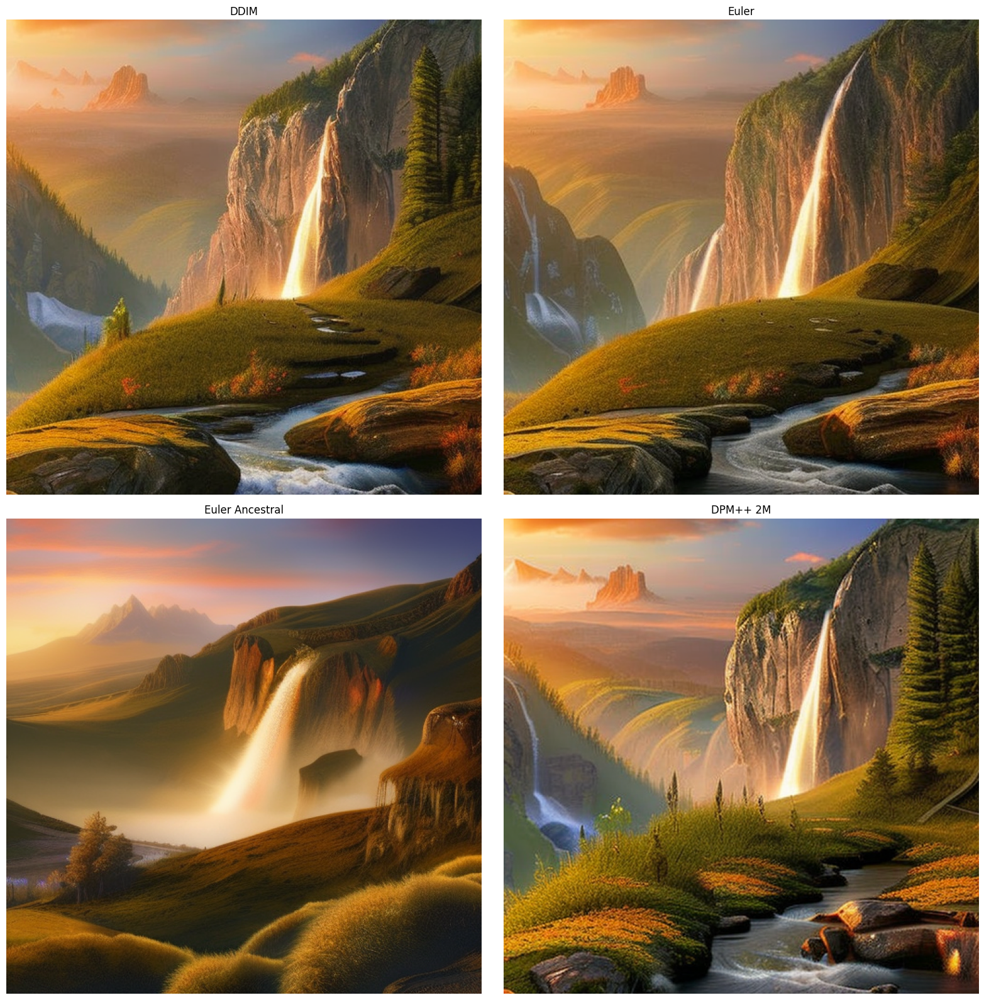


 Scheduler restaurado a DPM++ 2M


In [45]:
from diffusers import (
    DDIMScheduler,
    EulerDiscreteScheduler,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler
)
import torch

# ─────────────────────────────────────────────────────
# EXPERIMENTO: Comparación de Schedulers
# ─────────────────────────────────────────────────────

# SOLUCIÓN: En lugar de from_pretrained, usamos from_config y le pasamos
# la configuración del pipe que ya cargaste en el paso anterior.
# Esto evita el error 401 y es instantáneo.
schedulers = {
    "DDIM": DDIMScheduler.from_config(pipe.scheduler.config),
    "Euler": EulerDiscreteScheduler.from_config(pipe.scheduler.config),
    "Euler Ancestral": EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config),
    "DPM++ 2M": DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
}

prompt_sched = "a beautiful fantasy landscape, mountains, waterfall, golden hour, epic scenery"
negative_sched = "blurry, low quality, ugly"
SEED_SCHED = 42

imagenes_sched = []

for nombre_sched, scheduler in schedulers.items():
    print(f" Usando scheduler: {nombre_sched}...")
    pipe.scheduler = scheduler

    # IMPORTANTE: Definir el generador dentro del bucle para que cada
    # scheduler empiece con exactamente el mismo ruido inicial.
    gen = torch.Generator(device="cuda").manual_seed(SEED_SCHED)

    resultado = pipe(
        prompt=prompt_sched,
        negative_prompt=negative_sched,
        num_inference_steps=25,
        guidance_scale=7.5,
        height=512, width=512,
        generator=gen
    )
    imagenes_sched.append(resultado.images[0])

# Asegúrate de tener definida la función mostrar_galeria previamente
mostrar_galeria(imagenes_sched, titulos=list(schedulers.keys()), cols=2)

# Restaurar scheduler por defecto usando también from_config
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
print("\n Scheduler restaurado a DPM++ 2M")

## Módulo 8: Image-to-Image

**Image-to-Image** permite usar una imagen de entrada como punto de partida y transformarla según un nuevo prompt. Es ideal para:
- Cambiar el estilo artístico de una imagen
- Refinar bocetos o dibujos simples
- Añadir detalles a imágenes existentes

El parámetro `strength` (0.0 - 1.0) controla cuánto se transforma la imagen original:
- `strength = 0.1` → Pequeños cambios (muy similar al original)
- `strength = 0.5` → Transformación moderada
- `strength = 0.9` → Transformación radical (poco del original)

 Cargando pipeline Image-to-Image...
 Usando imagen de placeholder

Imagen de entrada:


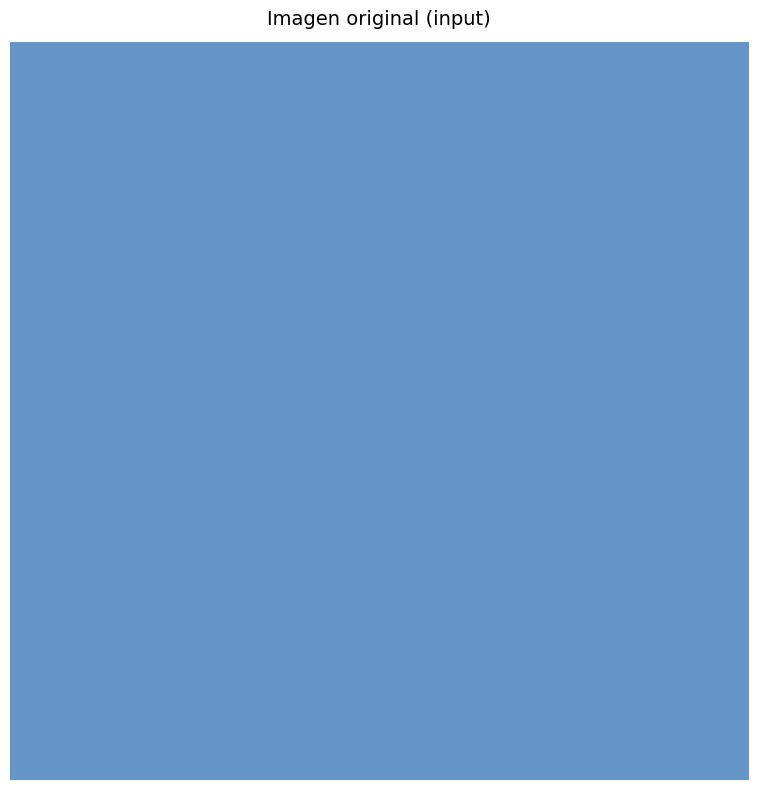

 Transformando estilo a acuarela...


  0%|          | 0/18 [00:00<?, ?it/s]


 Imagen transformada:


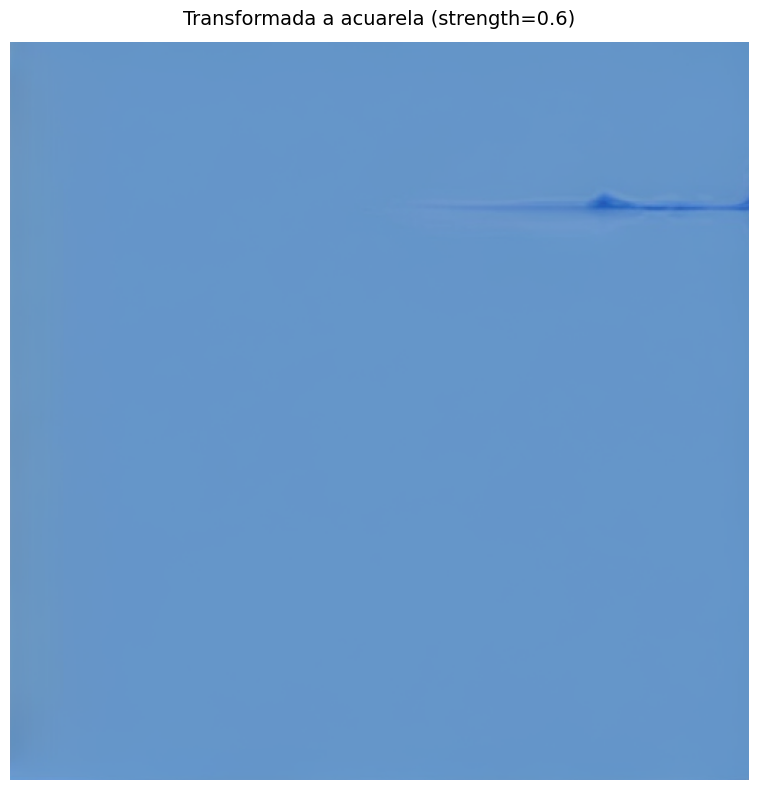

 Imagen guardada como: acuarela.png


In [46]:
from diffusers import StableDiffusionImg2ImgPipeline
from PIL import Image
import requests
from io import BytesIO

# Prompt principal (en inglés para mejor precisión del modelo)
prompt_realista = (
    "A detailed realistic oil painting of two majestic black horses facing each other with noses touching, "
    "graceful arched necks, realistic muscular anatomy, shiny dark coat, flowing mane, "
    "dramatic cinematic lighting, canvas texture, fine art masterpiece, rich colors"
)

# Prompt negativo (para eliminar el aspecto de tinta/boceto y evitar deformaciones)
negative_prompt_realista = (
    "blurry, low quality, watermark, signature, text"
)

# Cargar pipeline Image-to-Image desde el mismo modelo ya descargado
print(" Cargando pipeline Image-to-Image...")
img2img_pipe = StableDiffusionImg2ImgPipeline(
    vae=pipe.vae,
    text_encoder=pipe.text_encoder,
    tokenizer=pipe.tokenizer,
    unet=pipe.unet,
    scheduler=pipe.scheduler,
    safety_checker=None,
    feature_extractor=None,
    requires_safety_checker=False
).to("cuda")

# Imagen de entrada: usaremos la primera imagen generada (caballo)
# Alternativa: cargar cualquier imagen local
try:
    imagen_input = Image.open("caballo2.png").convert("RGB").resize((512, 512))
    print(" Usando imagen de un caballo input")
except:
    # Si no existe, crear imagen de ejemplo con color sólido
    imagen_input = Image.new('RGB', (512, 512), color=(100, 150, 200))
    print(" Usando imagen de placeholder")

# Mostrar imagen original
print("\nImagen de entrada:")
mostrar_imagen(imagen_input, titulo="Imagen original (input)")

# Transformar con nuevo estilo
print(" Transformando estilo a acuarela...")
gen = torch.Generator(device="cuda").manual_seed(42)

resultado_i2i = img2img_pipe(
    prompt=prompt_realista,
    negative_prompt=negative_prompt_realista,
    image=imagen_input,
    strength=0.6,             # 60% de transformación
    guidance_scale=7.5,
    num_inference_steps=30,
    generator=gen
)

imagen_transformada = resultado_i2i.images[0]
print("\n Imagen transformada:")
mostrar_imagen(imagen_transformada, titulo="Transformada a acuarela (strength=0.6)",
               guardar=True, nombre="acuarela.png")

##  Módulo 9: Gestión de Memoria GPU

La VRAM de la GPU es un recurso limitado. Estas son las mejores prácticas para gestionarla:

In [47]:
import gc

def memoria_gpu():
    """Imprime el estado actual de la memoria GPU."""
    allocated = torch.cuda.memory_allocated() / 1e9
    reserved = torch.cuda.memory_reserved() / 1e9
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    libre = total - reserved
    print(f"📊 Memoria GPU:")
    print(f"   Total:     {total:.2f} GB")
    print(f"   Usada:     {allocated:.2f} GB")
    print(f"   Reservada: {reserved:.2f} GB")
    print(f"   Libre:     {libre:.2f} GB")

def limpiar_memoria():
    """Libera la memoria GPU no utilizada."""
    gc.collect()
    torch.cuda.empty_cache()
    print(" Memoria GPU liberada")

# Verificar estado actual
print("Estado actual:")
memoria_gpu()

# Limpiar cache
limpiar_memoria()

print("\nDespués de limpieza:")
memoria_gpu()

print("""
 Consejos para ahorrar memoria:
   1. Usa torch.float16 siempre en GPU
   2. Habilita xformers: pipe.enable_xformers_memory_efficient_attention()
   3. Usa attention slicing: pipe.enable_attention_slicing()
   4. Genera imágenes de 512x512 en lugar de 768x768 si hay problemas de memoria
   5. Llama limpiar_memoria() entre experimentos
""")

Estado actual:
📊 Memoria GPU:
   Total:     15.64 GB
   Usada:     2.60 GB
   Reservada: 11.45 GB
   Libre:     4.18 GB
 Memoria GPU liberada

Después de limpieza:
📊 Memoria GPU:
   Total:     15.64 GB
   Usada:     2.60 GB
   Reservada: 3.61 GB
   Libre:     12.02 GB

 Consejos para ahorrar memoria:
   1. Usa torch.float16 siempre en GPU
   2. Habilita xformers: pipe.enable_xformers_memory_efficient_attention()
   3. Usa attention slicing: pipe.enable_attention_slicing()
   4. Genera imágenes de 512x512 en lugar de 768x768 si hay problemas de memoria
   5. Llama limpiar_memoria() entre experimentos



## Módulo 10: Ejercicio Libre – ¡Tu turno!

Ahora es tu momento de experimentar. Modifica los parámetros de la celda siguiente y observa los resultados.

### Ideas para explorar:
- Arquitectura: `"gothic cathedral interior, stained glass windows, divine light, ultra detailed"`
- Naturaleza: `"underwater coral reef, tropical fish, bioluminescent, cinematic"`
- Ciencia ficción: `"robot in a greenhouse tending flowers, solarpunk aesthetic, warm lighting"`
- Arte: `"portrait in the style of Klimt, golden patterns, art nouveau, detailed"`
- Urbano: `"aerial view of Tokyo at night, city lights, rain reflections, drone shot"`

 Memoria GPU liberada
 Generando tu imagen...
   Prompt: YOUR PROMPT HERE
   Seed: 42 | Steps: 30 | CFG: 7.5 | Tamaño: 768x768


  0%|          | 0/30 [00:00<?, ?it/s]

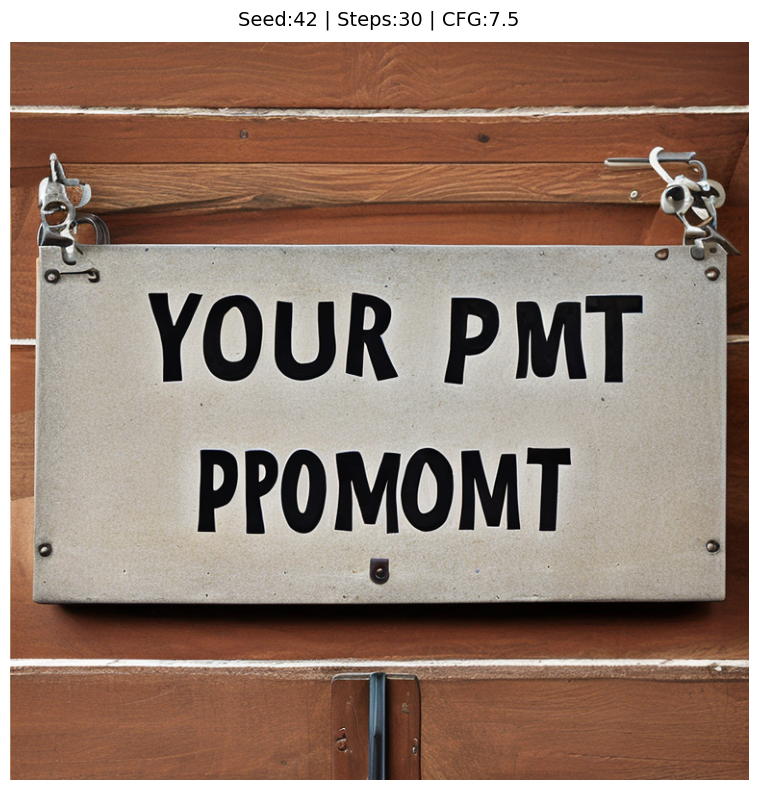

 Imagen guardada como: mi_creacion.png
Imagen guardada como 'mi_creacion.png'


In [48]:
# ════════════════════════════════════════════════════
#          ZONA DE EXPERIMENTACIÓN LIBRE
# ════════════════════════════════════════════════════

# ── Modifica estos parámetros ──────────────────────
MI_PROMPT = """YOUR PROMPT HERE"""

MI_NEGATIVE_PROMPT = "blurry, low quality, ugly, deformed, watermark, text, noise"

MI_SEED           = 42          # Entero cualquiera para reproducibilidad
MI_STEPS          = 30          # Entre 20 y 50 (más pasos = mejor calidad, más lento)
MI_CFG            = 7.5         # Entre 5.0 y 12.0 (mayor = más fiel al prompt)
MI_ANCHO          = 768         # Múltiplo de 64 (512, 768)
MI_ALTO           = 768         # Múltiplo de 64 (512, 768)
# ──────────────────────────────────────────────────

limpiar_memoria()  # Siempre limpiar antes de generar

gen = torch.Generator(device="cuda").manual_seed(MI_SEED)

print(f" Generando tu imagen...")
print(f"   Prompt: {MI_PROMPT[:80]}")
print(f"   Seed: {MI_SEED} | Steps: {MI_STEPS} | CFG: {MI_CFG} | Tamaño: {MI_ANCHO}x{MI_ALTO}")

resultado_libre = pipe(
    prompt=MI_PROMPT,
    negative_prompt=MI_NEGATIVE_PROMPT,
    num_inference_steps=MI_STEPS,
    guidance_scale=MI_CFG,
    height=MI_ALTO,
    width=MI_ANCHO,
    generator=gen
)

mi_imagen = resultado_libre.images[0]
mostrar_imagen(
    mi_imagen,
    titulo=f"Seed:{MI_SEED} | Steps:{MI_STEPS} | CFG:{MI_CFG}",
    guardar=True,
    nombre="mi_creacion.png"
)
print("Imagen guardada como 'mi_creacion.png'")

---

##  Resumen del Taller

### Lo que aprendiste:

| Concepto | Descripción |
|----------|-------------|
| **Modelos de Difusión** | El proceso forward/reverse de añadir y eliminar ruido |
| **Pipeline** | Cómo cargar y usar `StableDiffusionPipeline` |
| **Prompt Engineering** | Estructura efectiva de prompts y negative prompts |
| **CFG Scale** | Control de adherencia al prompt |
| **Inference Steps** | Balance entre velocidad y calidad |
| **Seeds** | Reproducibilidad y exploración de variaciones |
| **Schedulers** | Algoritmos de denoising y sus diferencias |
| **Image-to-Image** | Transformación de imágenes existentes |
| **Gestión de VRAM** | Buenas prácticas para memoria GPU |

### Recursos para seguir aprendiendo:

- [Documentación oficial de Diffusers](https://huggingface.co/docs/diffusers)
- [Hugging Face Hub – Modelos de difusión](https://huggingface.co/models?pipeline_tag=text-to-image)
- [Civitai – Modelos fine-tuned de la comunidad](https://civitai.com)
- [Stable Diffusion Art – Guías de prompts](https://stable-diffusion-art.com)
- [Paper original: High-Resolution Image Synthesis with LDMs](https://arxiv.org/abs/2112.10752)

---
*Taller creado con  Diffusers | Stable Diffusion 2.1 | Google Colab T4 GPU*